# Single transmon: ground & first excited energies with VQE and VQD

**Goal.** Estimate the two lowest energies $E_0, E_1$ of a transmon (and so the qubit frequency $\omega_{01}=E_1-E_0$) with
- **VQE** (Variational Quantum Eigensolver) → $E_0$
- **VQD** (Variational Quantum Deflation) → $E_1$

then run a few small experiments to pick settings that give the best estimates.

**Plan**
1. Build the transmon Hamiltonian, truncate it to $8$ levels and encode it on **3 qubits**.
2. Exact diagonalisation as the reference.
3. VQE + VQD implementations (statevector simulation, SciPy optimisers).
4. Experiments: ansatz & depth, optimiser, random restarts, VQD penalty $\beta$.
5. Final best estimates + a sweep over $E_J/E_C$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import cosm, eigh
from scipy.optimize import minimize
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.circuit.library import real_amplitudes, efficient_su2

rng = np.random.default_rng(7)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Transmon Hamiltonian

$$H = 4E_C\,\hat n^2 - E_J\cos\hat\varphi$$

We work in the harmonic-oscillator (Fock) basis, which is natural in the transmon regime $E_J/E_C \gg 1$:

$$\hat\varphi = \left(\tfrac{2E_C}{E_J}\right)^{1/4}(a+a^\dagger),\qquad
\hat n = \tfrac{i}{2}\left(\tfrac{E_J}{2E_C}\right)^{1/4}(a^\dagger-a)$$

The cosine is built in a large Fock space (40 levels) and *then* truncated to the lowest $d=8$ levels, so $\cos\hat\varphi$ is computed accurately. $8 = 2^3$ levels → 3 qubits.

Typical parameters: $E_J = 20$ GHz, $E_C = 0.25$ GHz ($E_J/E_C = 80$). All energies are in GHz (units of $h$).

In [14]:
def transmon_fock(EJ, EC, d=8, n_big=40):
    """Transmon Hamiltonian in the Fock basis, truncated to d levels."""
    a = np.diag(np.sqrt(np.arange(1, n_big)), 1)
    phi_zpf = (2 * EC / EJ) ** 0.25
    n_zpf = 0.5 * (EJ / (2 * EC)) ** 0.25
    phi = phi_zpf * (a + a.T)
    n = 1j * n_zpf * (a.T - a)
    H = 4 * EC * (n @ n) - EJ * cosm(phi)
    H = np.real(H)                      # H is real symmetric in this basis
    return 0.5 * (H + H.T)[:d, :d]

def transmon_charge_exact(EJ, EC, ng=0.0, ncut=4):
    """Reference: full charge-basis diagonalisation (no truncation issues)."""
    ns = np.arange(-ncut, ncut + 1)
    H = np.diag(4 * EC * (ns - ng) ** 2) - EJ / 2 * (np.eye(len(ns), k=1) + np.eye(len(ns), k=-1))
    return np.linalg.eigvalsh(H)

EJ, EC = 3.8740, 16.346
H_mat = transmon_fock(EJ, EC, d=4)
n_qubits = 3

# Encode the 8x8 matrix as a 3-qubit Pauli operator
H_op = SparsePauliOp.from_operator(H_mat).simplify()
print(f"Pauli terms: {len(H_op)}")

# Reference energies
evals_8 = np.linalg.eigvalsh(H_mat)
evals_full = transmon_charge_exact(EJ, EC)
E0_ex, E1_ex = evals_8[:2]
print(f"Exact (8-level, what VQE can reach):  E0 = {E0_ex:.6f}  E1 = {E1_ex:.6f}  w01 = {E1_ex-E0_ex:.6f} GHz")
print(f"Exact (full charge basis):            E0 = {evals_full[0]:.6f}  E1 = {evals_full[1]:.6f}  w01 = {evals_full[1]-evals_full[0]:.6f} GHz")
print(f"Simple estimate sqrt(8 EJ EC) - EC  =  {np.sqrt(8*EJ*EC) - EC:.4f} GHz")

Pauli terms: 6
Exact (8-level, what VQE can reach):  E0 = 3.258239  E1 = 11.662253  w01 = 8.404014 GHz
Exact (full charge basis):            E0 = -0.114591  E1 = 65.364873  w01 = 65.479465 GHz
Simple estimate sqrt(8 EJ EC) - EC  =  6.1617 GHz


The 8-level truncation is the target for the variational methods; its error with respect to the full model is a separate (and small) *truncation* error. Below, "error" always means error vs. the exact 8-level values.

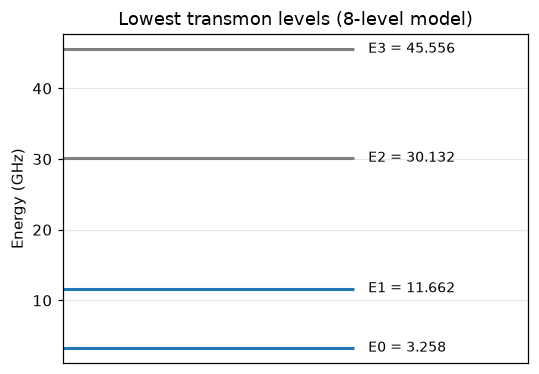

In [15]:
fig, ax = plt.subplots(figsize=(5, 3.5))
for k, E in enumerate(evals_8[:5]):
    ax.hlines(E, 0, 1, color="C0" if k < 2 else "gray", lw=2)
    ax.text(1.05, E, f"E{k} = {E:.3f}", va="center", fontsize=9)
ax.set_xlim(0, 1.6); ax.set_xticks([]); ax.set_ylabel("Energy (GHz)")
ax.set_title("Lowest transmon levels (8-level model)")
plt.tight_layout(); plt.show()

## 2. VQE and VQD

**VQE:** minimise $E(\theta) = \langle\psi(\theta)|H|\psi(\theta)\rangle$.

**VQD:** after finding $|\psi_0\rangle$, minimise
$$F(\theta) = \langle\psi(\theta)|H|\psi(\theta)\rangle + \beta\,|\langle\psi_0|\psi(\theta)\rangle|^2$$
The penalty pushes the state away from the ground state. It works only if $\beta > E_1 - E_0$ (here ≈ 6 GHz).

We use an exact statevector simulator. On real hardware the overlap would be measured with a compute–uncompute / swap test circuit.

In [16]:
def make_ansatz(kind="ry", reps=2, entanglement="full"):
    if kind == "ry":
        return real_amplitudes(n_qubits, reps=reps, entanglement=entanglement)
    if kind == "su2":
        return efficient_su2(n_qubits, reps=reps, entanglement=entanglement)
    raise ValueError(kind)

def state(ansatz, theta):
    return Statevector(ansatz.assign_parameters(theta))

def energy(ansatz, theta, H=None):
    return float(np.real(state(ansatz, theta).expectation_value(H_op if H is None else H)))

def run_opt(cost, n_params, method="L-BFGS-B", restarts=5, maxiter=2000):
    """Minimise `cost` from several random starts; return best result."""
    best, nfev = None, 0
    for _ in range(restarts):
        x0 = rng.uniform(-np.pi, np.pi, n_params)
        res = minimize(cost, x0, method=method, options={"maxiter": maxiter})
        nfev += res.nfev
        if best is None or res.fun < best.fun:
            best = res
    best.total_nfev = nfev
    return best

def vqe(ansatz, H=None, **kw):
    res = run_opt(lambda t: energy(ansatz, t, H), ansatz.num_parameters, **kw)
    return res.fun, state(ansatz, res.x), res

def vqd(ansatz, psi0, beta, H=None, **kw):
    def cost(t):
        psi = state(ansatz, t)
        e = np.real(psi.expectation_value(H_op if H is None else H))
        return e + beta * abs(psi0.inner(psi)) ** 2
    res = run_opt(cost, ansatz.num_parameters, **kw)
    psi1 = state(ansatz, res.x)
    E1 = float(np.real(psi1.expectation_value(H_op if H is None else H)))  # report the bare energy
    return E1, psi1, res

# Quick first run
ans = make_ansatz("ry", reps=2)
print(ans.draw(fold=-1))
E0, psi0, _ = vqe(ans)
E1, psi1, _ = vqd(ans, psi0, beta=20)
print(f"VQE  E0 = {E0:.6f}   error = {abs(E0-E0_ex):.2e}")
print(f"VQD  E1 = {E1:.6f}   error = {abs(E1-E1_ex):.2e}")
print(f"overlap |<psi0|psi1>|^2 = {abs(psi0.inner(psi1))**2:.2e}")

     ┌──────────┐          ┌──────────┐                      ┌──────────┐            
q_0: ┤ Ry(θ[0]) ├──■────■──┤ Ry(θ[3]) ├──────────────■────■──┤ Ry(θ[6]) ├────────────
     ├──────────┤┌─┴─┐  │  └──────────┘┌──────────┐┌─┴─┐  │  └──────────┘┌──────────┐
q_1: ┤ Ry(θ[1]) ├┤ X ├──┼───────■──────┤ Ry(θ[4]) ├┤ X ├──┼───────■──────┤ Ry(θ[7]) ├
     ├──────────┤└───┘┌─┴─┐   ┌─┴─┐    ├──────────┤└───┘┌─┴─┐   ┌─┴─┐    ├──────────┤
q_2: ┤ Ry(θ[2]) ├─────┤ X ├───┤ X ├────┤ Ry(θ[5]) ├─────┤ X ├───┤ X ├────┤ Ry(θ[8]) ├
     └──────────┘     └───┘   └───┘    └──────────┘     └───┘   └───┘    └──────────┘
VQE  E0 = 3.258239   error = 2.71e-13
VQD  E1 = 3.258239   error = 8.40e+00
overlap |<psi0|psi1>|^2 = 2.12e-15


## 3. Experiments

### Experiment 1 — ansatz type and depth
Compare `RealAmplitudes` (RY + CX, real amplitudes only) and `EfficientSU2` (RY+RZ + CX) for `reps` = 1…4. Since $H$ is real, real amplitudes should be enough and cheaper.

 ry reps=1  params= 6  |dE0|=8.06e-13  |dE1|=9.41e-14


 ry reps=2  params= 9  |dE0|=3.85e-10  |dE1|=3.30e-10


 ry reps=3  params=12  |dE0|=3.52e-11  |dE1|=4.00e-10


 ry reps=4  params=15  |dE0|=2.60e-11  |dE1|=2.64e-11


su2 reps=1  params=12  |dE0|=3.17e-07  |dE1|=8.81e-06


su2 reps=2  params=18  |dE0|=3.26e-06  |dE1|=1.11e-09


su2 reps=3  params=24  |dE0|=6.32e-06  |dE1|=4.40e-07


su2 reps=4  params=30  |dE0|=7.33e-10  |dE1|=2.26e-09


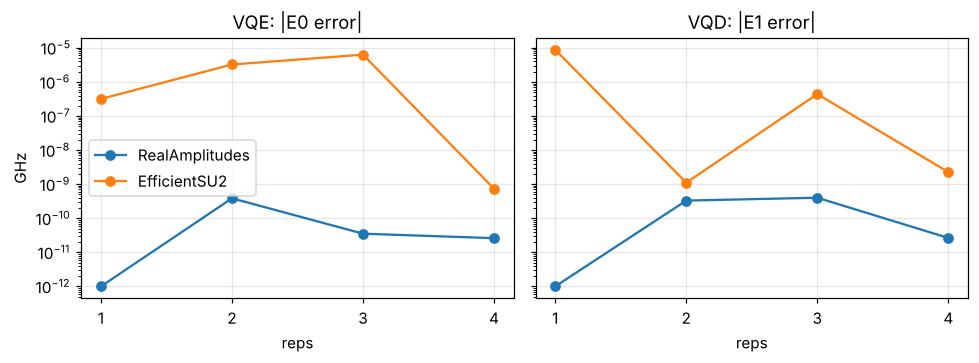

In [5]:
reps_list = [1, 2, 3, 4]
results_e1 = {}
for kind in ["ry", "su2"]:
    errs0, errs1, npar = [], [], []
    for r in reps_list:
        a = make_ansatz(kind, reps=r)
        e0, p0, _ = vqe(a, restarts=4)
        e1, _, _ = vqd(a, p0, beta=20, restarts=4)
        errs0.append(abs(e0 - E0_ex)); errs1.append(abs(e1 - E1_ex)); npar.append(a.num_parameters)
        print(f"{kind:>3} reps={r}  params={a.num_parameters:2d}  |dE0|={errs0[-1]:.2e}  |dE1|={errs1[-1]:.2e}")
    results_e1[kind] = (errs0, errs1, npar)

fig, axs = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for kind, lab in [("ry", "RealAmplitudes"), ("su2", "EfficientSU2")]:
    e0, e1, _ = results_e1[kind]
    axs[0].semilogy(reps_list, np.maximum(e0, 1e-12), "o-", label=lab)
    axs[1].semilogy(reps_list, np.maximum(e1, 1e-12), "o-", label=lab)
axs[0].set_title("VQE: |E0 error|"); axs[1].set_title("VQD: |E1 error|")
for ax in axs: ax.set_xlabel("reps"); ax.set_xticks(reps_list)
axs[0].set_ylabel("GHz"); axs[0].legend()
plt.tight_layout(); plt.show()

### Experiment 2 — classical optimiser
Fixed ansatz (`RealAmplitudes`, reps=3). Compare accuracy and cost (number of energy evaluations, which equals circuit runs on hardware).

     COBYLA: |dE0|=8.14e-08  |dE1|=4.90e-07  evals=5482


     Powell: |dE0|=8.93e-06  |dE1|=7.93e-05  evals=3207


Nelder-Mead: |dE0|=5.05e-11  |dE1|=4.05e-11  evals=7406


   L-BFGS-B: |dE0|=2.82e-12  |dE1|=2.84e-10  evals=1690


      SLSQP: |dE0|=2.24e-08  |dE1|=3.71e-08  evals=1511


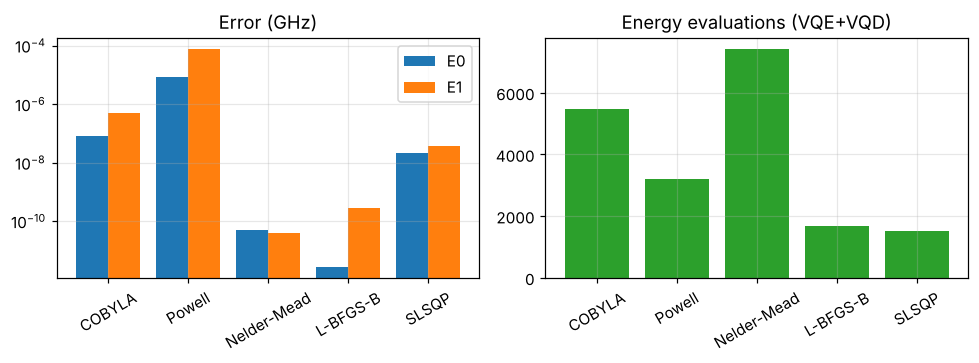

In [6]:
ans3 = make_ansatz("ry", reps=3)
methods = ["COBYLA", "Powell", "Nelder-Mead", "L-BFGS-B", "SLSQP"]
opt_rows = []
for m in methods:
    e0, p0, r0 = vqe(ans3, method=m, restarts=3)
    e1, _, r1 = vqd(ans3, p0, beta=20, method=m, restarts=3)
    opt_rows.append((m, abs(e0-E0_ex), abs(e1-E1_ex), r0.total_nfev + r1.total_nfev))
    print(f"{m:>11}: |dE0|={opt_rows[-1][1]:.2e}  |dE1|={opt_rows[-1][2]:.2e}  evals={opt_rows[-1][3]}")

fig, axs = plt.subplots(1, 2, figsize=(9, 3.4))
x = np.arange(len(methods))
axs[0].bar(x - 0.2, [max(r[1], 1e-12) for r in opt_rows], 0.4, label="E0")
axs[0].bar(x + 0.2, [max(r[2], 1e-12) for r in opt_rows], 0.4, label="E1")
axs[0].set_yscale("log"); axs[0].set_title("Error (GHz)"); axs[0].legend()
axs[1].bar(x, [r[3] for r in opt_rows], color="C2"); axs[1].set_title("Energy evaluations (VQE+VQD)")
for ax in axs: ax.set_xticks(x); ax.set_xticklabels(methods, rotation=30)
plt.tight_layout(); plt.show()

### Experiment 3 — random restarts (local minima)
Run VQE from 30 random initial points with a single start each. The spread shows why taking the best of several restarts helps.

converged to E0 (|err|<1e-4): 100% of runs


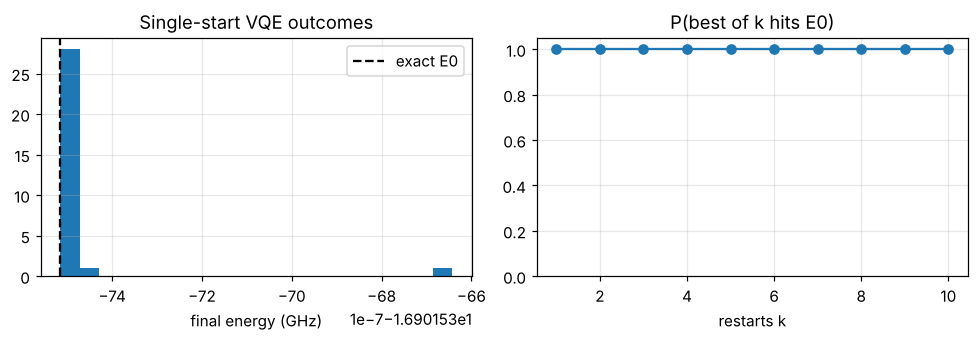

In [7]:
finals = []
for _ in range(30):
    x0 = rng.uniform(-np.pi, np.pi, ans3.num_parameters)
    finals.append(minimize(lambda t: energy(ans3, t), x0, method="L-BFGS-B").fun)
finals = np.array(finals)
dev = finals - E0_ex
print(f"converged to E0 (|err|<1e-4): {np.mean(dev < 1e-4)*100:.0f}% of runs")

# probability that best-of-k restarts reaches E0
p = np.mean(dev < 1e-4)
ks = np.arange(1, 11)
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
axs[0].hist(finals, bins=20); axs[0].axvline(E0_ex, color="k", ls="--", label="exact E0")
axs[0].set_xlabel("final energy (GHz)"); axs[0].set_title("Single-start VQE outcomes"); axs[0].legend()
axs[1].plot(ks, 1 - (1 - p) ** ks, "o-"); axs[1].set_ylim(0, 1.05)
axs[1].set_xlabel("restarts k"); axs[1].set_title("P(best of k hits E0)")
plt.tight_layout(); plt.show()

### Experiment 4 — VQD penalty $\beta$
Theory: need $\beta > E_1 - E_0 \approx 6$ GHz. Too small → VQD falls back to the ground state; very large → still correct but the cost landscape gets steeper.

beta=   0.5  E1=-16.90154  |dE1|=6.06e+00  overlap=1.00e+00


beta=   2.0  E1=-16.90154  |dE1|=6.06e+00  overlap=1.00e+00


beta=   4.0  E1=-16.90154  |dE1|=6.06e+00  overlap=1.00e+00


beta=   5.5  E1=-16.90154  |dE1|=6.06e+00  overlap=1.00e+00


beta=   6.5  E1=-10.83806  |dE1|=2.05e-11  overlap=1.80e-12


beta=   8.0  E1=-10.83806  |dE1|=9.80e-11  overlap=3.46e-11


beta=  12.0  E1=-10.83806  |dE1|=2.43e-11  overlap=1.03e-11


beta=  20.0  E1=-10.83806  |dE1|=4.31e-12  overlap=2.51e-13


beta=  50.0  E1=-10.83806  |dE1|=4.33e-11  overlap=5.61e-14


beta= 100.0  E1=-10.83806  |dE1|=1.45e-10  overlap=2.58e-14


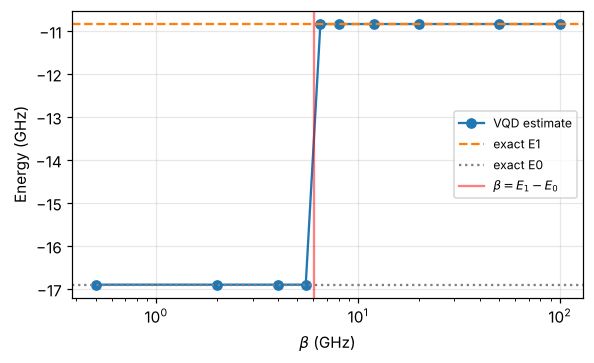

In [8]:
gap = E1_ex - E0_ex
_, psi0_best, _ = vqe(ans3, restarts=5)
betas = [0.5, 2, 4, 5.5, 6.5, 8, 12, 20, 50, 100]
beta_rows = []
for b in betas:
    e1, p1, _ = vqd(ans3, psi0_best, beta=b, restarts=3)
    beta_rows.append((b, e1, abs(psi0_best.inner(p1))**2))
    print(f"beta={b:6.1f}  E1={e1:.5f}  |dE1|={abs(e1-E1_ex):.2e}  overlap={beta_rows[-1][2]:.2e}")

fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.semilogx(betas, [r[1] for r in beta_rows], "o-", label="VQD estimate")
ax.axhline(E1_ex, color="C1", ls="--", label="exact E1")
ax.axhline(E0_ex, color="gray", ls=":", label="exact E0")
ax.axvline(gap, color="r", alpha=0.5, label=r"$\beta = E_1-E_0$")
ax.set_xlabel(r"$\beta$ (GHz)"); ax.set_ylabel("Energy (GHz)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Experiment 5 — shot noise (what a real device would give)
With exact statevectors everything above converges to ~$10^{-10}$. On hardware, each Pauli expectation $\langle P_k\rangle$ is estimated from a finite number of shots. We simulate this: for each of the 20 Pauli terms we draw `shots` ±1 outcomes with the correct probability (the VQD overlap is sampled too).

Compared:
- **COBYLA**: gradient-free, but it trusts each noisy value and tends to stop at "lucky" low samples.
- **SPSA**: the standard noisy-hardware optimiser. It estimates a gradient from 2 evaluations per step and averages the last iterates.

After optimising, the final circuit is **re-measured with $10^6$ shots** to give the reported energy.

COBYLA shots=   256  median |w01 error| =  3182.43 MHz


COBYLA shots=  1024  median |w01 error| =   536.91 MHz


COBYLA shots=  4096  median |w01 error| =   218.71 MHz


COBYLA shots= 16384  median |w01 error| =    81.34 MHz


  SPSA shots=   256  median |w01 error| =     8.89 MHz


  SPSA shots=  1024  median |w01 error| =     9.25 MHz


  SPSA shots=  4096  median |w01 error| =     1.42 MHz


  SPSA shots= 16384  median |w01 error| =     2.67 MHz


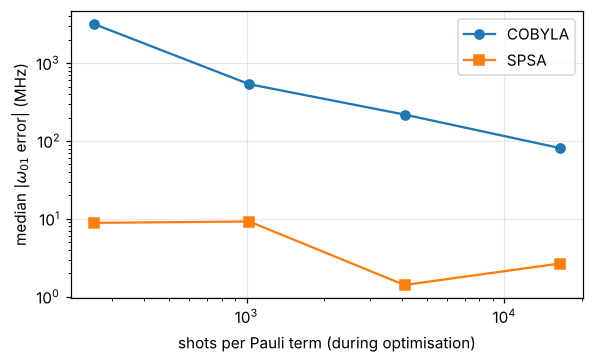

In [9]:
paulis = [SparsePauliOp(p) for p in H_op.paulis]
coeffs = np.real(H_op.coeffs)
is_id = np.array([set(str(p)) == {"I"} for p in H_op.paulis])

def noisy_energy(psi, shots):
    """Shot-sampled <H>: each Pauli term measured with `shots` shots."""
    exp = np.array([np.real(psi.expectation_value(P)) for P in paulis])
    est = 2 * rng.binomial(shots, np.clip((1 + exp) / 2, 0, 1)) / shots - 1
    est[is_id] = 1.0                      # identity term needs no measurement
    return float(coeffs @ est)

def noisy_overlap(psi0, psi, shots):
    return rng.binomial(shots, min(1.0, abs(psi0.inner(psi)) ** 2)) / shots

def spsa(f, x0, iters=300, a=0.3, c=0.2, A=30):
    """Minimal SPSA; returns the average of the last 25 iterates."""
    x, hist = x0.copy(), []
    for k in range(iters):
        ak, ck = a / (k + 1 + A) ** 0.602, c / (k + 1) ** 0.101
        d = rng.choice([-1, 1], len(x))
        x = x - ak * (f(x + ck * d) - f(x - ck * d)) / (2 * ck) * d
        hist.append(x.copy())
    return np.mean(hist[-25:], axis=0)

def optimise(f, npar, method):
    x0 = rng.uniform(-np.pi, np.pi, npar)
    if method == "SPSA":
        return spsa(f, x0)
    return minimize(f, x0, method="COBYLA", options={"maxiter": 600}).x

def noisy_vqe_vqd(ans, shots, method, beta=20, final_shots=1_000_000):
    n = ans.num_parameters
    x0 = optimise(lambda t: noisy_energy(state(ans, t), shots), n, method)
    psi0 = state(ans, x0)
    x1 = optimise(lambda t: noisy_energy(state(ans, t), shots)
                  + beta * noisy_overlap(psi0, state(ans, t), shots), n, method)
    psi1 = state(ans, x1)
    return noisy_energy(psi0, final_shots), noisy_energy(psi1, final_shots)

ans2 = make_ansatz("ry", reps=2)
shots_list = [256, 1024, 4096, 16384]
n_rep = 3
w_err = {"COBYLA": [], "SPSA": []}
for m in w_err:
    for s in shots_list:
        errs = [abs((e1 - e0) - (E1_ex - E0_ex)) for e0, e1 in
                (noisy_vqe_vqd(ans2, s, m) for _ in range(n_rep))]
        w_err[m].append(np.median(errs))
        print(f"{m:>6} shots={s:6d}  median |w01 error| = {w_err[m][-1]*1e3:8.2f} MHz")

fig, ax = plt.subplots(figsize=(5.5, 3.4))
for m, mk in [("COBYLA", "o-"), ("SPSA", "s-")]:
    ax.loglog(shots_list, np.array(w_err[m]) * 1e3, mk, label=m)
ax.set_xlabel("shots per Pauli term (during optimisation)")
ax.set_ylabel(r"median $|\omega_{01}$ error| (MHz)"); ax.legend()
plt.tight_layout(); plt.show()

## 4. Best configuration & final estimates

From the experiments:
- **Ansatz:** `RealAmplitudes`, full entanglement. Even reps = 1–2 is exact here, because $H$ is real and parity-symmetric (the ground state only uses even Fock levels, $E_1$ only odd ones), so few parameters are needed. `EfficientSU2` adds useless RZ parameters and converges slightly worse. We use reps = 2 as a safe margin.
- **Optimiser:** L-BFGS-B for exact simulation (most accurate per evaluation); **SPSA** when energies come from shots (COBYLA breaks down under noise).
- **Restarts:** this landscape is benign (all single starts converged), but best-of-3–5 is cheap insurance.
- **VQD penalty:** must exceed the gap (≈ 6.06 GHz; the sweep jumps exactly between 5.5 and 6.5). Use a few times the gap, e.g. $\beta \approx 20$.
- **With shots:** more shots during optimisation → better circuits; re-measuring the final circuit with many shots keeps the reported number from being dominated by noise.

In [10]:
best_ans = make_ansatz("ry", reps=2)
E0_v, psi0_v, r0 = vqe(best_ans, method="L-BFGS-B", restarts=5)
E1_v, psi1_v, r1 = vqd(best_ans, psi0_v, beta=20, method="L-BFGS-B", restarts=5)

print(f"{'':>8}{'VQE/VQD':>14}{'exact (8 lvl)':>16}{'abs error':>12}")
print(f"{'E0':>8}{E0_v:14.6f}{E0_ex:16.6f}{abs(E0_v-E0_ex):12.2e}")
print(f"{'E1':>8}{E1_v:14.6f}{E1_ex:16.6f}{abs(E1_v-E1_ex):12.2e}")
print(f"{'w01':>8}{E1_v-E0_v:14.6f}{E1_ex-E0_ex:16.6f}{abs((E1_v-E0_v)-(E1_ex-E0_ex)):12.2e}")
print(f"\nw01 full charge-basis model: {evals_full[1]-evals_full[0]:.6f} GHz  (truncation error {abs((E1_ex-E0_ex)-(evals_full[1]-evals_full[0])):.1e})")

               VQE/VQD   exact (8 lvl)   abs error
      E0    -16.901537      -16.901538    9.02e-07
      E1    -10.838058      -10.838059    1.08e-06
     w01      6.063478        6.063478    1.78e-07

w01 full charge-basis model: 6.063469 GHz  (truncation error 8.8e-06)


### Sweep over $E_J/E_C$
Repeat the best pipeline for several $E_J$ (fixed $E_C=0.25$ GHz) and compare the qubit frequency with exact results.

EJ/EC=   20  w01: VQE/VQD=2.88680  exact8=2.88680  full=2.88871


EJ/EC=   40  w01: VQE/VQD=4.20560  exact8=4.20560  full=4.20558


EJ/EC=   60  w01: VQE/VQD=5.21418  exact8=5.21418  full=5.21416


EJ/EC=   80  w01: VQE/VQD=6.06348  exact8=6.06348  full=6.06347


EJ/EC=  120  w01: VQE/VQD=7.48713  exact8=7.48712  full=7.48712


EJ/EC=  160  w01: VQE/VQD=8.68671  exact8=8.68671  full=8.68671


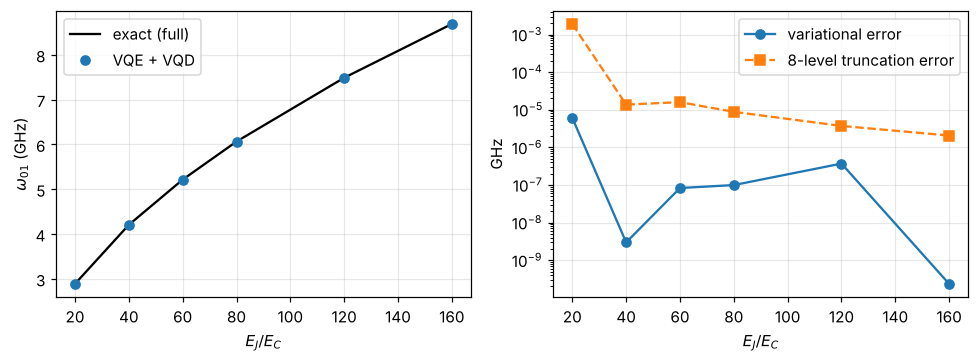

In [11]:
EJ_list = [5, 10, 15, 20, 30, 40]
w_vq, w_ex, w_full = [], [], []
for ej in EJ_list:
    Hm = transmon_fock(ej, EC, d=8)
    Hp = SparsePauliOp.from_operator(Hm)
    ev = np.linalg.eigvalsh(Hm); evf = transmon_charge_exact(ej, EC)
    e0, p0, _ = vqe(best_ans, H=Hp, restarts=5)
    e1, _, _ = vqd(best_ans, p0, beta=3 * (ev[1]-ev[0]) + 1, H=Hp, restarts=5)
    w_vq.append(e1 - e0); w_ex.append(ev[1]-ev[0]); w_full.append(evf[1]-evf[0])
    print(f"EJ/EC={ej/EC:5.0f}  w01: VQE/VQD={w_vq[-1]:.5f}  exact8={w_ex[-1]:.5f}  full={w_full[-1]:.5f}")

ratio = np.array(EJ_list) / EC
fig, axs = plt.subplots(1, 2, figsize=(9, 3.4))
axs[0].plot(ratio, w_full, "k-", label="exact (full)")
axs[0].plot(ratio, w_vq, "o", label="VQE + VQD")
axs[0].set_xlabel(r"$E_J/E_C$"); axs[0].set_ylabel(r"$\omega_{01}$ (GHz)"); axs[0].legend()
axs[1].semilogy(ratio, np.maximum(np.abs(np.array(w_vq) - w_ex), 1e-12), "o-", label="variational error")
axs[1].semilogy(ratio, np.abs(np.array(w_ex) - w_full), "s--", label="8-level truncation error")
axs[1].set_xlabel(r"$E_J/E_C$"); axs[1].set_ylabel("GHz"); axs[1].legend()
plt.tight_layout(); plt.show()

## 5. Takeaways
- With 3 qubits, a shallow `RealAmplitudes` ansatz reaches the exact 8-level $E_0$ and $E_1$ to numerical precision (~$10^{-10}$ GHz) in noiseless simulation.
- VQD works only for $\beta > E_1 - E_0$; below that it simply returns the ground state.
- With finite shots, the optimiser choice matters most: SPSA reaches a few-MHz error on $\omega_{01}$ with ~10³–10⁴ shots, where COBYLA can miss by hundreds of MHz or more.
- At small $E_J/E_C$ the 8-level Fock truncation (not the variational method) dominates the error, and charge dispersion (ignored in the Fock model) appears.

**Possible extensions:** a noisy device simulator (gate errors), measurement grouping of commuting Paulis, $E_2$ via a second VQD step to get the anharmonicity $\alpha = (E_2-E_1)-(E_1-E_0)$.